# Visualizations

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the pre-processed dataset
file_path = "europe_covid_cleaned9.csv"
df = pd.read_csv(file_path)

# Ensure date is in datetime format
df["date"] = pd.to_datetime(df["date"])

# Select 5 example countries
countries = ["Germany", "France", "Italy", "Spain", "Sweden"]
filtered_df = df[df["location"].isin(countries)]

# Add a numerical month column for sorting and consistent plotting
df["month_numeric"] = pd.to_datetime(df["date"]).dt.month
df["month_name"] = pd.to_datetime(df["date"]).dt.strftime('%B')

# Create a mapping for consistent month ordering
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

# Update filtered data with new columns
filtered_df = df[df["location"].isin(countries)]

### Line Plot – `new_cases_month_avg` over time 

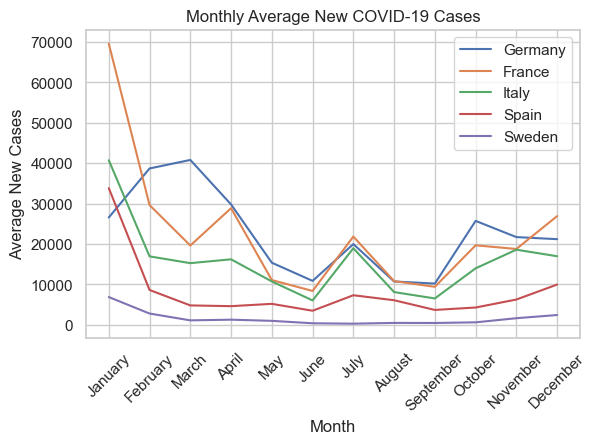

In [ ]:
# Set up the plotting style
sns.set(style="whitegrid")
plt.figure(figsize=(14, 4))

# Plot 1: Line plot of new_cases_month_avg over months
plt.subplot(1, 2, 1)
for country in countries:
    country_data = filtered_df[filtered_df["location"] == country]
    monthly_avg = country_data.groupby("month_name")["new_cases_month_avg"].mean().reindex(month_order)
    plt.plot(month_order, monthly_avg.values, label=country)

plt.title("Monthly Average New COVID-19 Cases")
plt.xlabel("Month")
plt.ylabel("Average New Cases")
plt.xticks(rotation=45)
plt.legend()

### Line Plot – `stringency_index` over time 

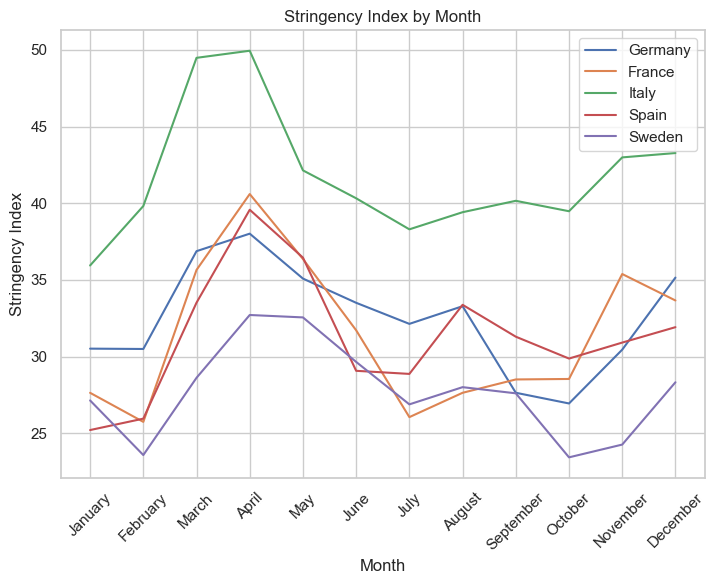

<Figure size 640x480 with 0 Axes>

In [ ]:
# Set up the plotting style
sns.set(style="whitegrid")
plt.figure(figsize=(14, 6))

# Plot 2: Line plot of stringency_index over months
plt.subplot(1, 2, 2)
for country in countries:
    country_data = filtered_df[filtered_df["location"] == country]
    monthly_stringency = country_data.groupby("month_name")["stringency_index"].mean().reindex(month_order)
    plt.plot(month_order, monthly_stringency.values, label=country)

plt.title("Stringency Index by Month")
plt.xlabel("Month")
plt.ylabel("Stringency Index")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()